In [65]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.layers import Dense, Input
from keras import Sequential
from keras.losses import MeanSquaredError, BinaryCrossentropy
from keras.activations import sigmoid

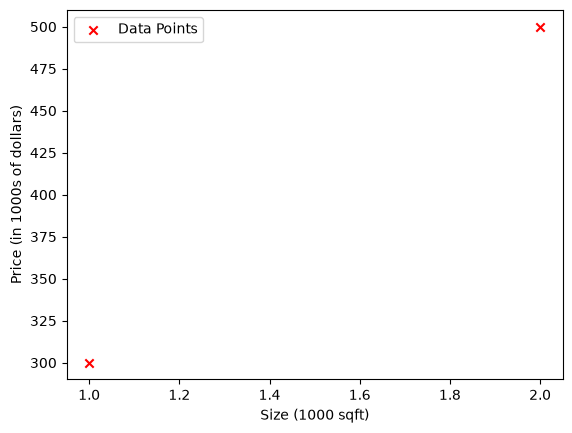

In [66]:
X_train = np.array([[1.0], [2.0]], dtype=np.float32)
y_train = np.array([[300.0], [500.0]], dtype=np.float32)

fig, ax = plt.subplots(1,1)
ax.scatter(X_train, Y_train, marker='x', c='r', label="Data Points")
ax.legend( fontsize='medium')
ax.set_ylabel('Price (in 1000s of dollars)', fontsize='medium')
ax.set_xlabel('Size (1000 sqft)', fontsize='medium')
plt.show()

In [67]:
linear_layer = tf.keras.layers.Dense(units=1, activation = 'linear', )

In [68]:
linear_layer.get_weights()

[]

In [69]:
a1 = linear_layer(X_train[0].reshape(1,1))
print(a1)

tf.Tensor([[1.2087814]], shape=(1, 1), dtype=float32)


In [70]:
w, b= linear_layer.get_weights()
print(f"w = {w}, b={b}")

w = [[1.2087814]], b=[0.]


In [71]:
set_w = np.array([[200]])
set_b = np.array([100])

linear_layer.set_weights([set_w, set_b])
print(linear_layer.get_weights())

[array([[200.]], dtype=float32), array([100.], dtype=float32)]


In [72]:

a1 = linear_layer(X_train[0].reshape(1,1))
print(a1)
alin = np.dot(set_w,X_train[0].reshape(1,1)) + set_b
print(alin)


tf.Tensor([[300.]], shape=(1, 1), dtype=float32)
[[300.]]


In [73]:
prediction_tf = linear_layer(X_train)
prediction_np = np.dot( X_train, set_w) + set_b

In [75]:
print(X_train.shape)
print(y_train.shape)

(2, 1)
(2, 1)


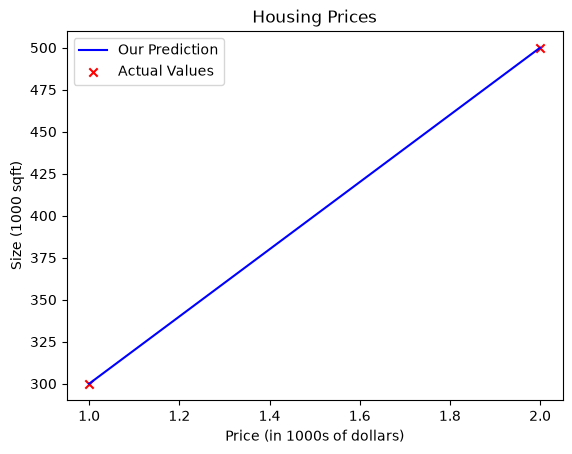

In [76]:
plt.plot(X_train,prediction_np,c='b',label='Our Prediction')
plt.scatter(X_train,y_train,marker='x',c='r',label='Actual Values')
plt.title("Housing Prices")
plt.xlabel("Price (in 1000s of dollars)")
plt.ylabel("Size (1000 sqft)")
plt.legend()
plt.show()

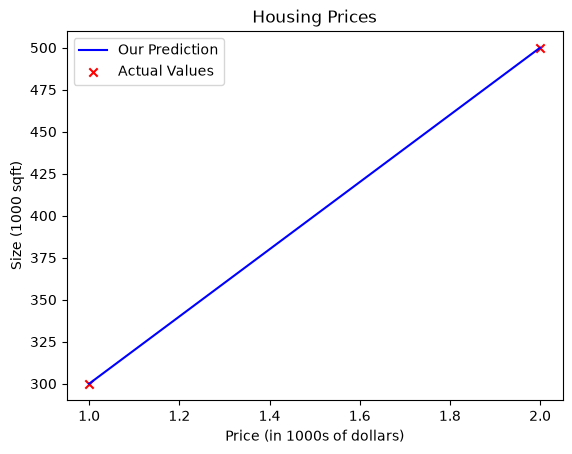

In [77]:
plt.plot(X_train,prediction_tf,c='b',label='Our Prediction')
plt.scatter(X_train,y_train,marker='x',c='r',label='Actual Values')
plt.title("Housing Prices")
plt.xlabel("Price (in 1000s of dollars)")
plt.ylabel("Size (1000 sqft)")
plt.legend()
plt.show()

In [78]:
X_train = np.array([0., 1, 2, 3, 4, 5], dtype=np.float32).reshape(-1,1)
Y_train = np.array([0,  0, 0, 1, 1, 1], dtype=np.float32).reshape(-1,1)

In [79]:
pos = Y_train == 1
neg = Y_train == 0

In [86]:
model = Sequential(
    [
        tf.keras.layers.Dense(1,input_dim=1,activation='sigmoid',name='L1')
    ]
)

/Users/yaman/Derslerim/Ekstra Dersler/Machine Learning Specialization/Advanced Learning Algorithms/Practises/venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [87]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ L1 (Dense)                      │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

In [89]:
logistic_layer = model.get_layer('L1')
w,b = logistic_layer.get_weights()
print(w,b)
print(w.shape,b.shape)

[[0.15777373]] [0.]
(1, 1) (1,)


In [90]:
set_w = np.array([[2]])
set_b = np.array([-4.5])
logistic_layer.set_weights([set_w,set_b])
print(logistic_layer.get_weights())

[array([[2.]], dtype=float32), array([-4.5], dtype=float32)]


In [95]:
def log_sigmoid(z):
    g = 1/(1+np.exp(-z))
    return g

In [96]:
a1=model.predict(X_train[0].reshape(1,1))
print(a1)
alog=log_sigmoid(np.dot(X_train[0].reshape(1,1),set_w)+set_b)
print(alog)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
[[0.01098694]]
[[0.01098694]]
